<a href="https://colab.research.google.com/github/tpeoples1911/Data-Science-Research-Assignments/blob/main/Copy_of_HomeworkAssignmentv3_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 1 Overview:

## Homework Overview

This homework overview is presented by Thojae C. Peoples for Dr. Richard Young, instructor of MIS 769, during the Fall 2026 semester.

The primary objective of this assignment is to conduct an exploratory analysis of a randomly selected dataset obtained from Hugging Face. Through Exploratory Data Analysis (EDA), I will examine the dataset to identify patterns, trends, relationships, anomalies, and other potentially meaningful insights contained within the data.

The analysis will generally follow the framework provided for the assignment while incorporating modifications and additional analytical techniques for further exploration and learning. These additions are intended to expand upon the required material, strengthen my understanding of the analytical process, and provide opportunities to experiment with methods beyond the minimum assignment requirements.

Throughout the analysis, I will document relevant observations, interpretations, and additional insights that emerge from the data. The following research and analytical questions will serve as a guide for the EDA and represent the primary questions I intend to address by the conclusion of this overview.

### AI and External Resource Disclosure

Grammarly, Claude, and Gemini were used as supplemental tools to assist with research, search results, writing refinement, and the exploration of relevant concepts during the development of this work. These tools were used to support the research and learning process rather than replace my own analysis, interpretation, or conclusions.

For transparency and proper attribution, I will also identify and reference relevant external resources used throughout my work. In future assignments, this may include complementary videos, books, articles, documentation, tutorials, or other educational materials that I find useful and incorporate into my learning or analysis. When such resources contribute to my work, I will make an effort to appropriately acknowledge and credit the original authors, creators, and owners of that information.

**Q1: Which data source did you use (Kaggle or HuggingFace)? Why did you choose it?**



**Q2: What did you learn from exploring your dataset with .describe() and .value_counts()?**



**Q3: What data quality issues did you find (missing values, duplicates, outliers)? How might these affect analysis?**



**Q4: What interesting pattern or insight did you discover in your data? Why is it interesting or surprising?**



#Purpose of this assingment
### Dataset Loading and Data Quality Assessment

The first objective is to load the selected dataset from Hugging Face into Google Colab and conduct an initial Data Quality Assessment (DQA). This assessment will evaluate the overall structure, completeness, consistency, and reliability of the dataset before proceeding with further exploratory analysis.

The Data Quality Assessment will include an examination of missing values, duplicate records, potential outliers, data types, unique values, and other relevant information that I deem useful. Additional checks may be incorporated as necessary based on the characteristics and structure of the dataset.

At the conclusion of the assessment, I will write out my insights and provide a brief summary of the steps I may do differently in the future.

# The Data Science Pipeline

This is the pipeline that will be followed for this assingment.

1. Load Data
2. Clean Data
3. Explore
4. Insight

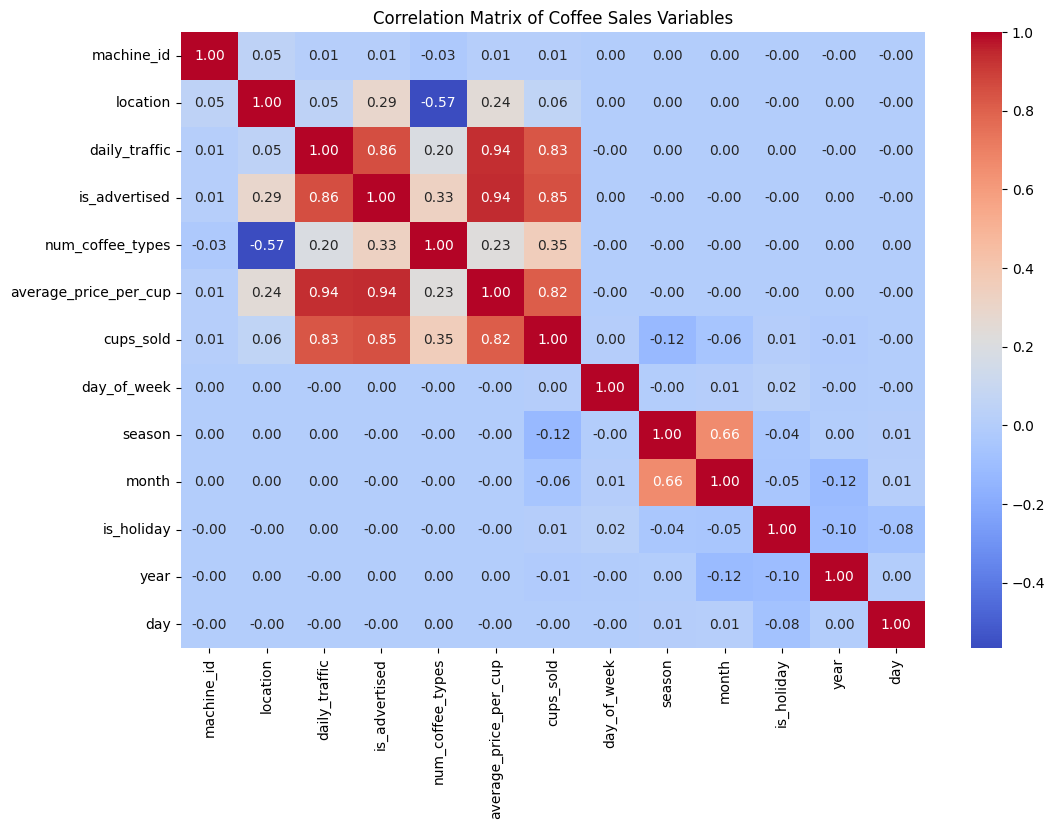

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlations,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Coffee Sales Variables")
plt.show()

# Phase 1  | Environment Setup








In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import seaborn as sns
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import ( mean_absolute_error,mean_squared_error,
    r2_score)
import warnings
warnings.filterwarnings('ignore')

# Set display options
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', 100)

print("✅ Libraries imported!")
print(f"   Pandas version: {pd.__version__}")
print(f"   NumPy version: {np.__version__}")



✅ Libraries imported!
   Pandas version: 2.2.3
   NumPy version: 2.1.3


# Phase 2  | Load Data








In [ ]:
# The dataset I chose from hugging face is data about Coffee Sales

#Load data from HuggingFace
from datasets import load_dataset

# Choose ONE dataset by uncommenting:

# Neuronetties/coffee_sales_data(~104k rows)
dataset = load_dataset("neuronetties/coffee_sales_data", split="train")

# Convert to pandas DataFrame
df = dataset.to_pandas()

print(f"✅ Loaded {len(df):,} records from HuggingFace")
print(f"   Columns: {list(df.columns)}")

✅ Loaded 103,500 records from HuggingFace
   Columns: ['machine_id', 'location', 'daily_traffic', 'is_advertised', 'num_coffee_types', 'average_price_per_cup', 'cups_sold', 'day_of_week', 'season', 'month', 'is_holiday', 'year', 'day']


In [ ]:
print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)
print(f"Number of rows: {len(df):,}")
print(f"Number of columns: {len(df.columns)}")
print(f"\nColumn names: {list(df.columns)}")
print(f"\nData types:")
print(df.dtypes)

DATASET OVERVIEW
Number of rows: 103,500
Number of columns: 13

Column names: ['machine_id', 'location', 'daily_traffic', 'is_advertised', 'num_coffee_types', 'average_price_per_cup', 'cups_sold', 'day_of_week', 'season', 'month', 'is_holiday', 'year', 'day']

Data types:
machine_id                 int64
location                   int64
daily_traffic              int64
is_advertised              int64
num_coffee_types           int64
average_price_per_cup    float64
cups_sold                  int64
day_of_week                int64
season                     int64
month                      int64
is_holiday                 int64
year                       int64
day                        int64
dtype: object


In [ ]:
print(df.describe())
print(df.value_counts())

          machine_id      location  daily_traffic  is_advertised  \
count  103500.000000  103500.00000   103500.00000    103500.0000   
mean       49.500000       2.00000     1839.42000         0.4000   
std        28.866209       1.41422     1050.15575         0.4899   
min         0.000000       0.00000      564.00000         0.0000   
25%        24.750000       1.00000      785.25000         0.0000   
50%        49.500000       2.00000     1790.50000         0.0000   
75%        74.250000       3.00000     2648.25000         1.0000   
max        99.000000       4.00000     4012.00000         1.0000   

       num_coffee_types  average_price_per_cup      cups_sold    day_of_week  \
count      103500.00000          103500.000000  103500.000000  103500.000000   
mean            8.40000              87.450000      31.037179       2.999034   
std             1.49667               6.039566      10.113899       2.000734   
min             6.00000              81.700000      18.000000      

In [ ]:
# Print the first few rows of the DataFrame
print(df.head())

   machine_id  location  daily_traffic  is_advertised  num_coffee_types  \
0           0         0           1982              0                 8   
1           0         0           1982              0                 8   
2           0         0           1982              0                 8   
3           0         0           1982              0                 8   
4           0         0           1982              0                 8   

   average_price_per_cup  cups_sold  day_of_week  season  month  is_holiday  \
0                  83.75         30            5       1      1           1   
1                  83.75         27            6       1      1           0   
2                  83.75         32            0       1      1           0   
3                  83.75         28            1       1      1           0   
4                  83.75         40            2       1      1           0   

   year  day  
0  2022    1  
1  2022    2  
2  2022    3  
3  2022    4  

# Phase 3 | Data Quality Assessment

Here is where I check for missing values and run explatory analysis to see what areas of gaps my data may have.  

## 3.1 | Missing Values
Here we check for missing values from the dataset.

In [ ]:

# Check for missing values
print("=" * 60)
print("MISSING VALUES ANALYSIS")
print("=" * 60)

missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    'Column': missing.index,
    'Missing Count': missing.values,
    'Missing %': missing_pct.values
})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)

if len(missing_df) > 0:
    print("\n⚠️ Columns with missing values:")
    print(missing_df.to_string(index=False))
else:
    print("\n✅ No missing values found!")

print(f"\nTotal cells: {df.size:,}")
print(f"Missing cells: {df.isnull().sum().sum():,}")
print(f"Completeness: {(1 - df.isnull().sum().sum() / df.size) * 100:.2f}%")

MISSING VALUES ANALYSIS

✅ No missing values found!

Total cells: 1,345,500
Missing cells: 0
Completeness: 100.00%


## 3.2 | Duplicate Records
Here we see if we have any duplicates within the dataset.

In [ ]:
# Check for duplicate rows
print("=" * 60)
print("DUPLICATE RECORDS ANALYSIS")
print("=" * 60)

duplicates = df.duplicated().sum()
duplicate_pct = (duplicates / len(df) * 100)

print(f"\nTotal rows: {len(df):,}")
print(f"Duplicate rows: {duplicates:,}")
print(f"Duplicate percentage: {duplicate_pct:.2f}%")

if duplicates > 0:
    print("\n⚠️ Sample duplicate rows:")
    print(df[df.duplicated(keep=False)].head())
else:
    print("\n✅ No duplicate rows found!")

DUPLICATE RECORDS ANALYSIS

Total rows: 103,500
Duplicate rows: 0
Duplicate percentage: 0.00%

✅ No duplicate rows found!


## 3.3  | Outliers

Here we test to find outliers in the dataset, though exlcuding some rows such as machine_id,location, days of the week,season,month,is holiday,year since they do not have as much relevance in terms of outliers that I would want to see for this analysis.

In [ ]:
# Identify numeric columns and check for outliers
print("=" * 60)
print("OUTLIER ANALYSIS (Numeric Columns)")
print("=" * 60)

# Variables to exclude from outlier analysis
exclude_cols = ["machine_id","location","day_of_week","season","month","is_holiday",
    "year","day"]

# Select numeric columns, excluding specified variables
numeric_cols = [
    col for col in df.select_dtypes(include=[np.number]).columns
    if col not in exclude_cols
]

print(f"\nNumeric columns analyzed: {numeric_cols}")

if len(numeric_cols) > 0:
    for col in numeric_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = df[
            (df[col] < lower_bound) |
            (df[col] > upper_bound)
        ]

        outlier_pct = len(outliers) / len(df) * 100

        print(f"\n📊 {col}:")
        print(f"   Range: {df[col].min():.2f} to {df[col].max():.2f}")
        print(
            f"   Mean: {df[col].mean():.2f}, "
            f"Median: {df[col].median():.2f}"
        )
        print(
            f"   IQR Bounds: {lower_bound:.2f} to {upper_bound:.2f}"
        )
        print(
            f"   Outliers: {len(outliers):,} "
            f"({outlier_pct:.1f}%)"
        )

else:
    print("\nNo numeric columns found for outlier analysis.")

OUTLIER ANALYSIS (Numeric Columns)

Numeric columns analyzed: ['daily_traffic', 'is_advertised', 'num_coffee_types', 'average_price_per_cup', 'cups_sold']

📊 daily_traffic:
   Range: 564.00 to 4012.00
   Mean: 1839.42, Median: 1790.50
   IQR Bounds: -2009.25 to 5442.75
   Outliers: 0 (0.0%)

📊 is_advertised:
   Range: 0.00 to 1.00
   Mean: 0.40, Median: 0.00
   IQR Bounds: -1.50 to 2.50
   Outliers: 0 (0.0%)

📊 num_coffee_types:
   Range: 6.00 to 10.00
   Mean: 8.40, Median: 8.00
   IQR Bounds: 5.00 to 13.00
   Outliers: 0 (0.0%)

📊 average_price_per_cup:
   Range: 81.70 to 97.50
   Mean: 87.45, Median: 83.75
   IQR Bounds: 70.55 to 103.75
   Outliers: 0 (0.0%)

📊 cups_sold:
   Range: 18.00 to 74.00
   Mean: 31.04, Median: 28.00
   IQR Bounds: -3.50 to 64.50
   Outliers: 28 (0.0%)


## 3.4 Correlation for Cups Sold

This test to see which variable has a negative or positive relationship to the variable of Cups Sold.

In [ ]:
correlations = df.corr(numeric_only=True)

print(
    correlations["cups_sold"]
    .sort_values(ascending=False)
)

cups_sold                1.000000
is_advertised            0.853070
daily_traffic            0.833928
average_price_per_cup    0.815555
num_coffee_types         0.353342
location                 0.058907
machine_id               0.010875
is_holiday               0.007562
day_of_week              0.002358
day                     -0.001886
year                    -0.012267
month                   -0.058419
season                  -0.121395
Name: cups_sold, dtype: float64


### 3.4. - Part 2 | Correlation Heatmap

Creating a heatmap of the correlation that was identifed in part 1.

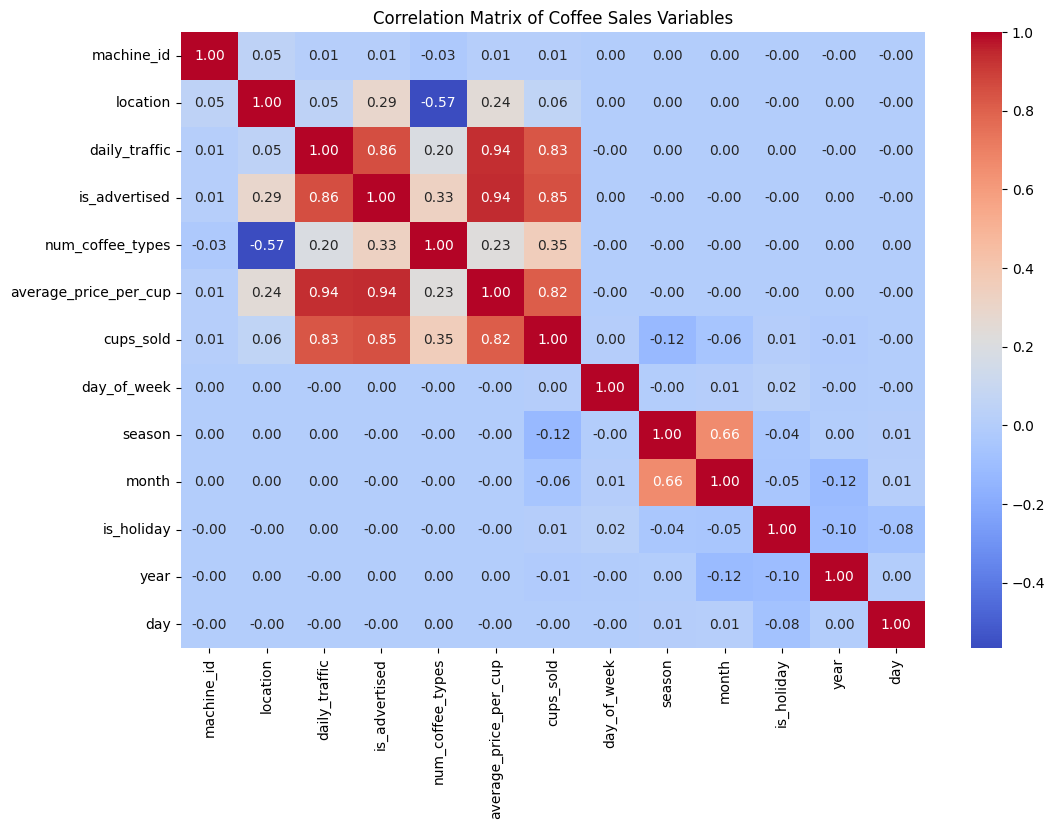

In [ ]:

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlations,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Coffee Sales Variables")
plt.show()

## 3.5 Linear Regression | Predictive Modeling

Here I decided to implement linear regression due to the statistics courses I taking to include just wanting to shed some more practice with creating predictive models.

We will use the features:
daily_traffic
is_advertised
average_price_per_cup
num_coffee_types

To target the amount of cups sold.

In [ ]:
features = [
    "daily_traffic",
    "is_advertised",
    "average_price_per_cup",
    "num_coffee_types"
]

target = "cups_sold"

model_df = df[
    features + [target]
].copy()

print(model_df.head())

print("\nMissing values:")
print(model_df.isnull().sum())

   daily_traffic  is_advertised  average_price_per_cup  num_coffee_types  \
0           1982              0                  83.75                 8   
1           1982              0                  83.75                 8   
2           1982              0                  83.75                 8   
3           1982              0                  83.75                 8   
4           1982              0                  83.75                 8   

   cups_sold  
0         30  
1         27  
2         32  
3         28  
4         40  

Missing values:
daily_traffic            0
is_advertised            0
average_price_per_cup    0
num_coffee_types         0
cups_sold                0
dtype: int64


### 3.5.1 | Creating the X and y (Inputs and Target Variables)

Here I start by first creating my inputs and outcomes.

In [ ]:
X = model_df[features]
y = model_df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (103500, 4)
y shape: (103500,)


### 3.5.2 | Train / Test Split

Here I train my model but first splitting the data into what I want to train and test. I split the data 80/20.

In [ ]:
# Train / Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 82800
Testing observations: 20700


### 3.5.3 | Linear Regression Model

For this section, I created a linear regression model to see how well the selected variables could be used to predict coffee sales.

Before training the model, I used the median for measures of central tendency to account for any missing values and standardized the numerical data so the variables were on a similar scale. I then trained the model using the training data and used the test data to generate predictions for cups_sold.

This allowed me to later compare the predicted sales with the actual sales and evaluate how well the model performed.

In [ ]:
# Linear Regression Model
linear_model = Pipeline([

    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler()),

    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


### 3.5.4 | Linear Regression Results

The MAE tells me that my model's prediction is off about 3.3 cups.

The RMSE being at 4.5 which is higher than my MAE, this could mean that some predicted sales deviate a lot more than the actual. Reasons for this could mean I could have included more predictors in my outliers test and not exluded so many possibly, which could have changed my MAE and RSME.

Lastly, my R squared shows that the predictors I chose account for roughly 80% of the data.

In [ ]:
# Linear Regression Results

linear_mae = mean_absolute_error(y_test,linear_predictions)

linear_rmse = np.sqrt(mean_squared_error(y_test,linear_predictions))

linear_r2 = r2_score(y_test,linear_predictions)

print("=" * 50)
print("LINEAR REGRESSION RESULTS")
print("=" * 50)

print(f"MAE:  {linear_mae:.2f}")
print(f"RMSE: {linear_rmse:.2f}")
print(f"R²:   {linear_r2:.4f}")

LINEAR REGRESSION RESULTS
MAE:  3.32
RMSE: 4.50
R²:   0.8025


# Phase 4 | Additional Exploration

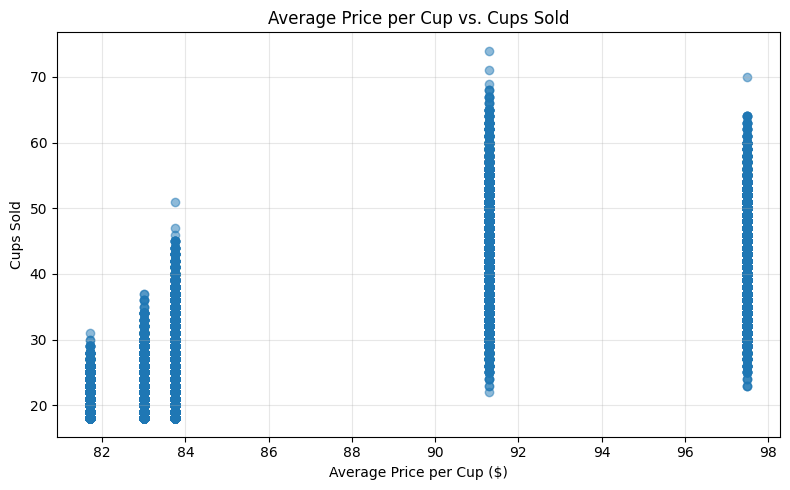

Correlation between price and cups sold: 0.816


In [ ]:

# YOUR EXPLORATION CODE HERE
# Price vs. Cups Sold

plt.figure(figsize=(8, 5))

plt.scatter(
    df["average_price_per_cup"],
    df["cups_sold"],
    alpha=0.5
)

plt.title("Average Price per Cup vs. Cups Sold")
plt.xlabel("Average Price per Cup ($)")
plt.ylabel("Cups Sold")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate the correlation
price_correlation = df[
    ["average_price_per_cup", "cups_sold"]
].corr().iloc[0, 1]

print(
    f"Correlation between price and cups sold: "
    f"{price_correlation:.3f}"
)


# Example: Distribution of a text column's length

# Find text columns
text_cols = df.select_dtypes(include=['object']).columns.tolist()
if len(text_cols) > 0:
    text_col = text_cols[0]  # Use first text column
    df['text_length'] = df[text_col].astype(str).str.len()

    print(f"📊 Text Length Analysis for '{text_col}':")
    print(f"   Shortest: {df['text_length'].min()} characters")
    print(f"   Longest: {df['text_length'].max()} characters")
    print(f"   Average: {df['text_length'].mean():.0f} characters")

    plt.figure(figsize=(10, 4))
    plt.hist(df['text_length'], bins=50, edgecolor='black', alpha=0.7)
    plt.xlabel('Text Length (characters)')
    plt.ylabel('Frequency')
    plt.title(f'Distribution of Text Length in {text_col}')
    plt.axvline(df['text_length'].mean(), color='red', linestyle='--', label=f'Mean: {df["text_length"].mean():.0f}')
    plt.legend()
    plt.show()

# Phase 5: Write-Up Summary Review
This assessment of coffee sales helped me identify several interesting insights while working in a new environment using Google Colab and Hugging Face. It also allowed me to apply statistical concepts and methods from my previous R courses within a Python-based environment.

One interesting finding was that the RMSE was higher than the MAE, indicating that some larger prediction errors affected the model's overall performance. This could potentially be related to variables or other factors that were not fully accounted for during my analysis, particularly since I chose to exclude certain features from the outlier analysis.

I followed the general framework demonstrated by Dr. Young for this assignment, while adding additional analyses and modifying certain elements to further explore the dataset and improve my understanding of the process.

In the future, I plan to continue using Hugging Face because it provides access to datasets that may be useful for personal projects while also giving me another environment and resource for continued learning.

If I were to redo or expand this assignment, I would consider creating additional features and implementing a Random Forest model alongside the Linear Regression model to compare their predictive performance.

I would also revisit the outlier analysis and investigate special events and holidays more closely to determine whether they are associated with significant increases or decreases in coffee sales. This would allow me to better understand what the data actually shows and whether these external factors have a meaningful relationship with sales.

# Response to Questions

Q1: Which data source did you use (Kaggle or HuggingFace)? Why did you choose it?

Your answer:  

**HuggingFace, I wanted to try something new and challenge myself on doing a new method instead of using Kaggle or loading live datasets that I have utilized before in previous work**



Q2: What did you learn from exploring your dataset with .describe() and .value_counts()?

Your answer:

**When I explored the dataset using .describe(). and .value_counts, the daily traffic average is over 1,000 days. There is a lot of variation within that feature. The coffee sales as well has a wide range and it lets me to believe if I were to plot this out, the emperical rule would not apply due to the possible right skewness that would be present from looking at how the mean is lower than the median**

Q3: What data quality issues did you find (missing values, duplicates, outliers)? How might these affect analysis?

Your answer:

**Data quality issues that I found was that I exluded to many features possibly which results is my root mean squared error being higher than my MAE. I hypothesize that if I included more features and possibly created new features, those numbers would change a good deal**

Q4: What interesting pattern or insight did you discover in your data? Why is it interesting or surprising?

**The interesting pattern I seen from first just viewing the data and then viewing it on the heatmap, was that there is a great deal of correlation between coffee that is advertised and sold along with quite a few features. This makes things could for analysis and business predicitons of what areas to target**
